# Main Notebook for whole diabetes risk prediction 


In [2]:
# %pip install -q pandas numpy matplotlib seaborn scikit-learn joblib streamlit

In [6]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from preprocessing import (
    load_data,
    clean_data,
    split_data,
    fit_preprocessors,
    transform,
    save_split,
)          # our preprocessing pre-defined functions

sns.set_theme(style="whitegrid") 

In [7]:
# loading the Dataset via predefined methods
df_raw = load_data()
df_raw.head()

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


In [8]:
df_raw.shape

(100000, 9)

#### 100k Rows with 9 Columns/Features. 
##### We would need different numbers of features for different models but the meaning and features would be same

In [9]:
dfRaw = df_raw

In [10]:
dfRaw.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  str    
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  str    
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), str(2)
memory usage: 8.0 MB


In [11]:
dfRaw.describe()

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,diabetes
count,100000.000000,100000.00000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,41.885856,0.07485,0.039420,27.320767,5.527507,138.058060,0.085000
std,22.516840,0.26315,0.194593,6.636783,1.070672,40.708136,0.278883
min,0.080000,0.00000,0.000000,10.010000,3.500000,80.000000,0.000000
25%,24.000000,0.00000,0.000000,23.630000,4.800000,100.000000,0.000000
50%,43.000000,0.00000,0.000000,27.320000,5.800000,140.000000,0.000000
75%,60.000000,0.00000,0.000000,29.580000,6.200000,159.000000,0.000000
max,80.000000,1.00000,1.000000,95.690000,9.000000,300.000000,1.000000


In [14]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
gender,100000,3,Female,58552,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,100000.0,NaN,NaN,NaN,41.885856,22.51684,0.08,24.0,43.0,60.0,80.0
hypertension,100000.0,NaN,NaN,NaN,0.07485,0.26315,0.0,0.0,0.0,0.0,1.0
heart_disease,100000.0,NaN,NaN,NaN,0.03942,0.194593,0.0,0.0,0.0,0.0,1.0
smoking_history,100000,6,No Info,35816,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bmi,100000.0,NaN,NaN,NaN,27.320767,6.636783,10.01,23.63,27.32,29.58,95.69
HbA1c_level,100000.0,NaN,NaN,NaN,5.527507,1.070672,3.5,4.8,5.8,6.2,9.0
blood_glucose_level,100000.0,NaN,NaN,NaN,138.05806,40.708136,80.0,100.0,140.0,159.0,300.0
diabetes,100000.0,NaN,NaN,NaN,0.085,0.278883,0.0,0.0,0.0,0.0,1.0


with this single eda describe we know a lot about the dataset's features themselve.
1. there are two string data so we have to normalize and encode them.
2. there is lot of garbage in `smoking_history` feature.
3. Much more.

~ funny shi there is `0.08` year as datapoint in age like wha-


Now, standarization, normalization, duplicate removing, and null removing

In [16]:
dfRaw.isnull().sum()

gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64

In [17]:
# no null : D still we will see to frame
dfRaw.isnull().sum().to_frame("missing_values")

,missing_values
gender,0
age,0
hypertension,0
heart_disease,0
smoking_history,0
bmi,0
HbA1c_level,0
blood_glucose_level,0
diabetes,0


In [22]:
targetCounts = dfRaw["diabetes"].value_counts()
display(" so 8.5 % have diabetes " ) 
targetCounts

' so 8.5 % have diabetes '

diabetes
0    91500
1     8500
Name: count, dtype: int64

,counts,percentage
diabetes,,
0,91500,91.5
1,8500,8.5


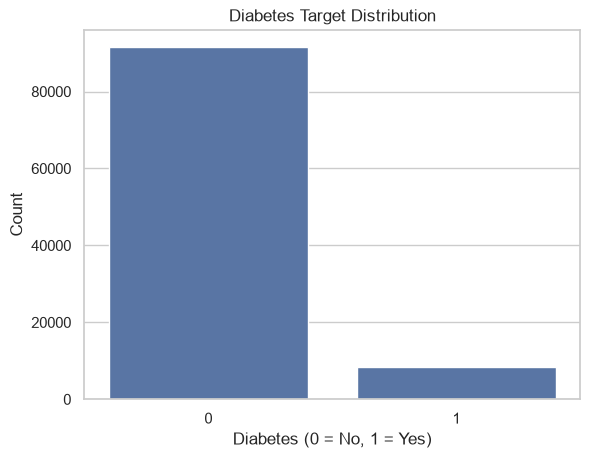

In [23]:
targetPercentage = (
    df_raw["diabetes"].value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

display(pd.DataFrame({
    "counts" : targetCounts,
    "percentage" : targetPercentage
}))

sns.countplot(data = dfRaw, x = "diabetes")
plt.title("Diabetes Target Distribution")
plt.xlabel("Diabetes (0 = No, 1 = Yes)")
plt.ylabel("Count")
plt.show()
    

 as earlier explained by me that there are two features in string.
which are known as categorial values or features. those are
`smoking_history` and `gender`

In [24]:
categorical_cols = ["gender", "smoking_history"]

for col in categorical_cols:
    print(f"\n{col.upper()} distribution:")
    display(df_raw[col].value_counts().to_frame("count"))

    print(f"{col.upper()} diabetes rate:")
    display(
        df_raw.groupby(col)["diabetes"]
        .agg(["count", "mean"])
        .rename(columns={"mean": "diabetes_rate"})
        .sort_values("diabetes_rate", ascending=False)
        .round(3)
    )


GENDER distribution:


,count
gender,
Female,58552
Male,41430
Other,18


GENDER diabetes rate:


,count,diabetes_rate
gender,,
Male,41430,0.097
Female,58552,0.076
Other,18,0.000



SMOKING_HISTORY distribution:


,count
smoking_history,
No Info,35816
never,35095
former,9352
current,9286
not current,6447
ever,4004


SMOKING_HISTORY diabetes rate:


,count,diabetes_rate
smoking_history,,
former,9352,0.170
ever,4004,0.118
not current,6447,0.107
current,9286,0.102
never,35095,0.095
No Info,35816,0.041


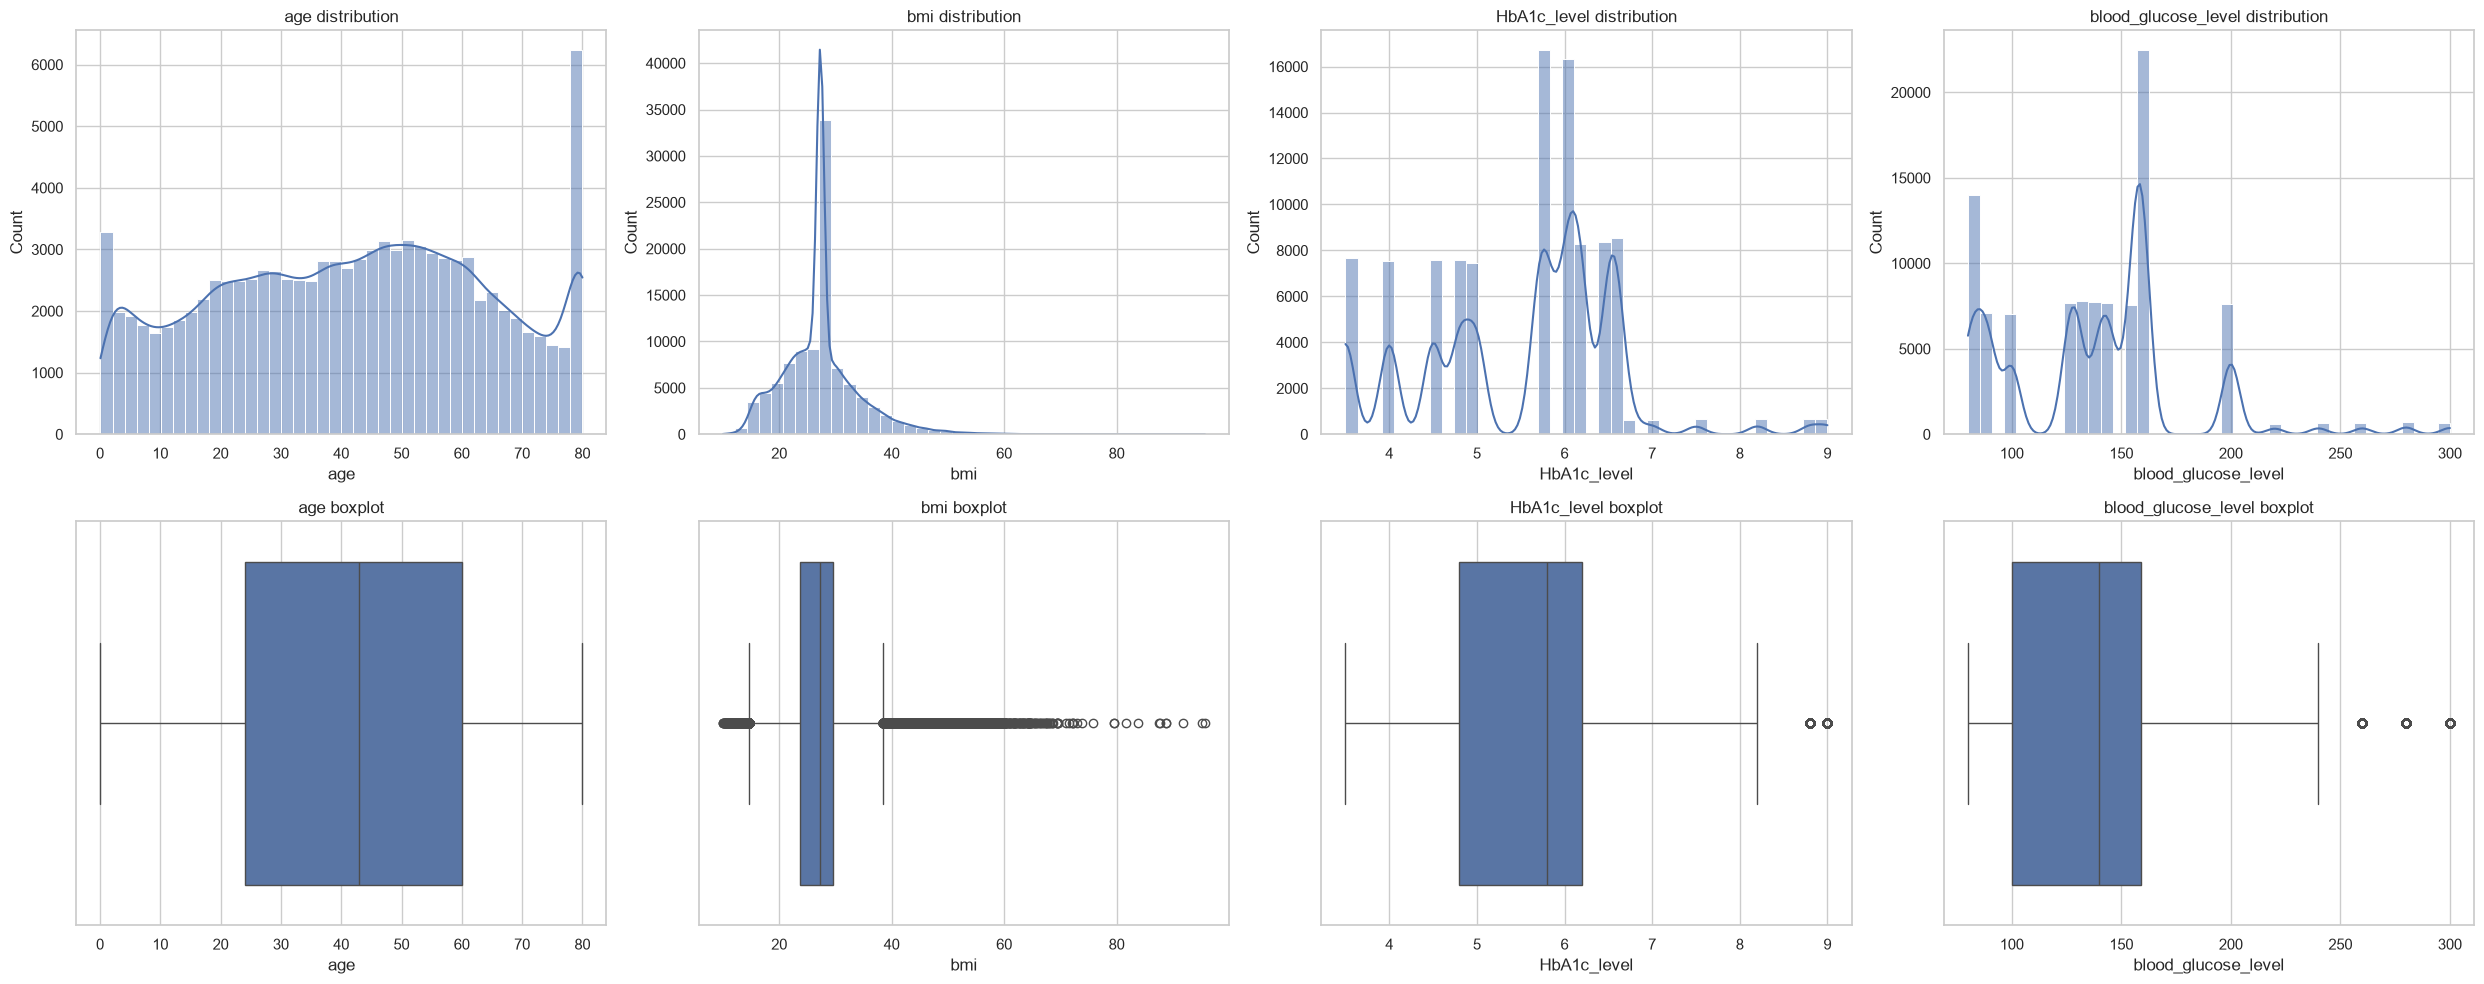

In [31]:
# now let's see the numerical distribution using subplots with box ( for outliers ) 
# and hist for various-ness

numeric_cols = ["age", "bmi", "HbA1c_level", "blood_glucose_level"]

fig, axes = plt.subplots(2,4, figsize=(25,10))

for i, col in enumerate(numeric_cols):
    sns.histplot(data=df_raw, x=col, bins=40, kde=True, ax=axes[0, i])
    axes[0, i].set_title(f"{col} distribution")

    sns.boxplot(data=df_raw, x=col, ax=axes[1, i])
    axes[1, i].set_title(f"{col} boxplot")

plt.tight_layout()
plt.show()

In [33]:
print("Age <= 0:", (df_raw["age"] <= 0).sum())
print("BMI < 10:", (df_raw["bmi"] < 10).sum())
print("BMI > 80:", (df_raw["bmi"] > 80).sum())
print("Gender = Other:", (df_raw["gender"] == "Other").sum())

# the data rules for age and bmi we check it and then clean it

display(df_raw[numeric_cols].quantile([0.01, 0.05, 0.50, 0.95, 0.99]).T)

Age <= 0: 0
BMI < 10: 0
BMI > 80: 9
Gender = Other: 18


,0.01,0.05,0.50,0.95,0.99
age,1.08,4.00,43.00,80.00,80.0000
bmi,14.60,16.82,27.32,39.49,48.7901
HbA1c_level,3.50,3.50,5.80,6.60,8.8000
blood_glucose_level,80.00,80.00,140.00,200.00,280.0000


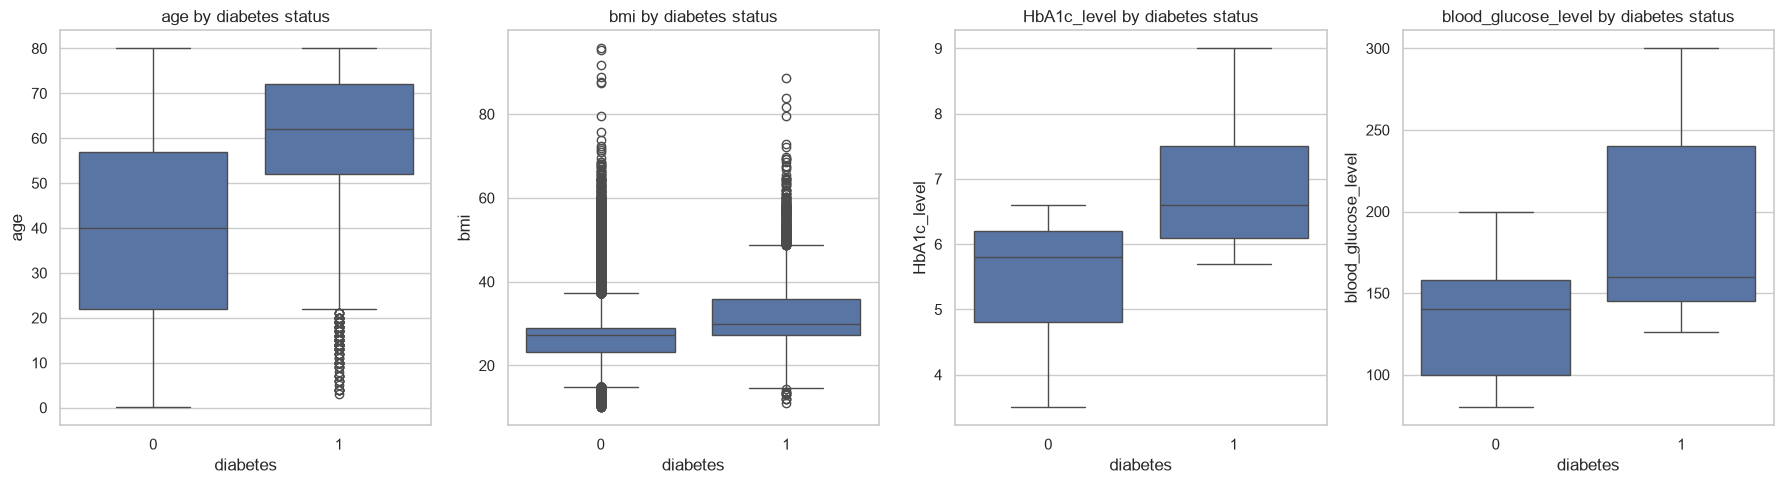

In [34]:
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

for i, col in enumerate(numeric_cols):
    sns.boxplot(data=df_raw, x="diabetes", y=col, ax=axes[i])
    axes[i].set_title(f"{col} by diabetes status")

plt.tight_layout()
plt.show()

Checking the target with numeric values

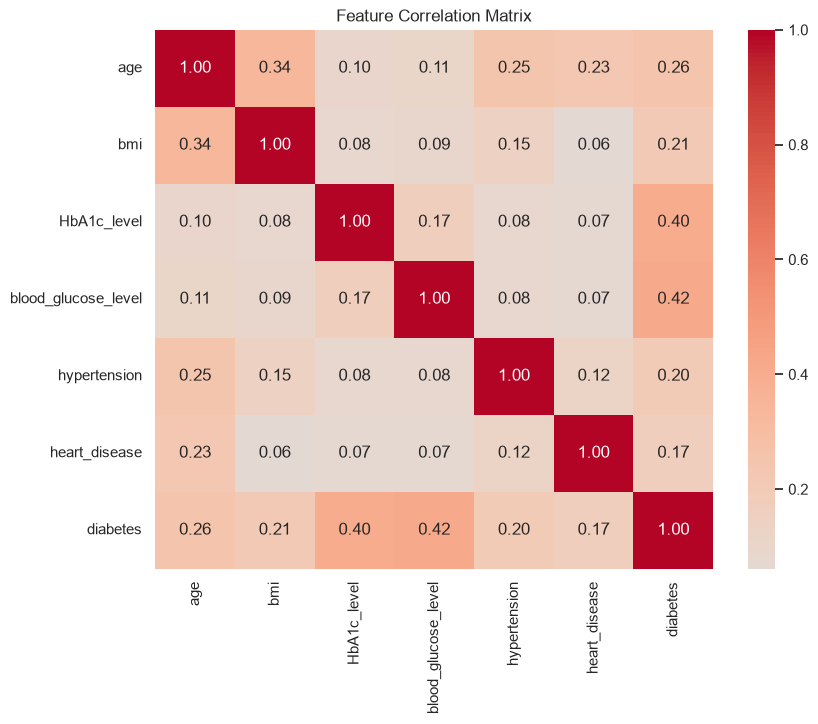

In [36]:
# ofcc we have to check correlation : D

correlation_cols = numeric_cols + ["hypertension", "heart_disease", "diabetes"]

plt.figure(figsize=(9, 7))
sns.heatmap(
    df_raw[correlation_cols].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
)
plt.title("Feature Correlation Matrix")
plt.show()